# Pós-IA-ML / Mineração de Dados e ETL (Extract, Transform, Load)
## Avaliação / Atividade 2

## **Nome do aluno:** Charles Balmant Villalba
## Link do COLAB: https://colab.research.google.com/drive/1jAZDWKTqcchmS39AXXypmLFvWxDMLNmK?usp=sharing

# 1. Apresentação da Base de Dados


### 1.1. Base de Dados Escolhida (nome)

Brazilian Houses to Rent, versão `houses_to_rent_v2.csv`. A base contém 10.692 registros de imóveis anunciados para aluguel e 13 colunas. Os imóveis estão localizados em Belo Horizonte, Campinas, Porto Alegre, Rio de Janeiro e São Paulo.

### 1.2. Base de Dados Escolhida (link)

[Link](https://raw.githubusercontent.com/marcos-s1/Aluguel/master/houses_to_rent_v2.csv)

### 1.3. Descrição da temática da base de dados

Este trabalho investiga em que medida a cidade e as características de um imóvel ajudam a estimar seu valor de aluguel anunciado. A base permite analisar características como área, número de quartos e banheiros, vagas de garagem e presença de mobília em anúncios de cinco cidades brasileiras.

A análise é relevante para entender como os preços anunciados variam entre cidades e entre imóveis com características semelhantes. A Mineração de Dados pode contribuir identificando padrões nessas diferenças e treinando um modelo de regressão para estimar o aluguel em reais. O modelo pode ser avaliado em registros reservados para teste, usando o erro médio absoluto para medir, em reais, a diferença média entre o aluguel previsto e o anunciado.


# 2. Conhecimento e compreensão dos dados (Antes de aplicar qualquer transformação, é necessário conhecer a base de dados).


In [19]:
import pandas as pd

url = (
    "https://raw.githubusercontent.com/marcos-s1/"
    "Aluguel/master/houses_to_rent_v2.csv"
)

dados = pd.read_csv(url)

display(dados.head())

,city,area,rooms,bathroom,parking spaces,floor,animal,furniture,hoa (R$),rent amount (R$),property tax (R$),fire insurance (R$),total (R$)
0,São Paulo,70,2,1,1,7,acept,furnished,2065,3300,211,42,5618
1,São Paulo,320,4,4,0,20,acept,not furnished,1200,4960,1750,63,7973
2,Porto Alegre,80,1,1,1,6,acept,not furnished,1000,2800,0,41,3841
3,Porto Alegre,51,2,1,0,2,acept,not furnished,270,1112,22,17,1421
4,São Paulo,25,1,1,0,1,not acept,not furnished,0,800,25,11,836


###  2.1. Identificar a quantidade de registros (linhas)

In [20]:
linhas, colunas = dados.shape

print(f"Quantidade de registros: {linhas:,}".replace(",", "."))
print(f"Quantidade de colunas: {colunas}")

Quantidade de registros: 10.692
Quantidade de colunas: 13


A base contém 10.692 registros e 13 colunas. Cada linha corresponde a um registro de imóvel anunciado para aluguel.


### 2.2. Identificar a variável-alvo (quando existir)

A variável-alvo escolhida é `rent amount (R$)`, que representa o valor do aluguel anunciado, em reais. É uma variável numérica monetária registrada em reais inteiros no arquivo. A tarefa de previsão é de regressão.

A coluna `total (R$)` faz parte da descrição da base, mas deve ser excluída das variáveis preditoras quando o modelo for treinado. Como o custo total já inclui o aluguel, usá-lo como entrada causaria vazamento de dados.

In [21]:
variavel_alvo = "rent amount (R$)"

print(f"Variável-alvo: {variavel_alvo}")
print(f"Tipo no pandas: {dados[variavel_alvo].dtype}")

display(dados[variavel_alvo].describe())

Variável-alvo: rent amount (R$)
Tipo no pandas: int64


,rent amount (R$)
count,10692.000000
mean,3896.247194
std,3408.545518
min,450.000000
25%,1530.000000
50%,2661.000000
75%,5000.000000
max,45000.000000


### 2.3. Identificar o significado de cada variável e os tipos de dados

In [22]:
resumo_colunas = pd.DataFrame({
    "Variável": dados.columns,
    "Tipo no pandas": dados.dtypes.astype(str).to_numpy(),
    "Exemplo de valor": dados.iloc[0].to_numpy(),
})

display(resumo_colunas)

,Variável,Tipo no pandas,Exemplo de valor
0,city,object,São Paulo
1,area,int64,70
2,rooms,int64,2
3,bathroom,int64,1
4,parking spaces,int64,1
5,floor,object,7
6,animal,object,acept
7,furniture,object,furnished
8,hoa (R$),int64,2065
9,rent amount (R$),int64,3300


| Variável | Significado | Tipo de dado |
|---|---|---|
| `city` | Cidade onde o imóvel está localizado | Categórico nominal |
| `area` | Área do imóvel em metros quadrados | Numérico, registrado em valores inteiros |
| `rooms` | Número de quartos | Numérico discreto |
| `bathroom` | Número de banheiros | Numérico discreto |
| `parking spaces` | Número de vagas de garagem | Numérico discreto |
| `floor` | Andar do imóvel. O arquivo também contém o código `-` | Ordinal, armazenado como texto |
| `animal` | Indica se o imóvel aceita animais de estimação | Categórico binário |
| `furniture` | Indica se o imóvel é mobiliado | Categórico binário |
| `hoa (R$)` | Valor da taxa de condomínio em reais | Numérico monetário |
| `rent amount (R$)` | Valor do aluguel anunciado em reais. É a variável-alvo | Numérico monetário |
| `property tax (R$)` | Valor do imposto sobre o imóvel (IPTU) em reais | Numérico monetário |
| `fire insurance (R$)` | Valor do seguro contra incêndio em reais | Numérico monetário |
| `total (R$)` | Custo total registrado, incluindo aluguel e encargos | Numérico monetário |

# 3. Limpeza dos dados (Verificar se existem problemas nos registros e atributos).


## 3.1. Identificar valores ausentes:

In [23]:
import pandas as pd

ausentes = dados.replace(r"^\s*$", pd.NA, regex=True).isna()
contagem = ausentes.sum()
colunas_com_ausentes = contagem[contagem > 0]

if colunas_com_ausentes.empty:
    print("Nenhum valor nulo ou vazio encontrado na base.")
else:
    print("Quantidade de valores ausentes por coluna:")
    display(colunas_com_ausentes)

    print("Percentual de valores ausentes por cidade:")
    display(
        ausentes[colunas_com_ausentes.index]
        .groupby(dados["city"], dropna=False)
        .mean()
        .mul(100)
        .round(2)
    )

Nenhum valor nulo ou vazio encontrado na base.


Existe uma interpretação incorreta, já que pode ser que existam valores com "-", que serão considerados como preenchidos, porém, são valores vazios.

In [24]:
vazios = dados.replace(r"^\s*$", pd.NA, regex=True).isna().sum().sum()
hifens = dados["floor"].astype("string").str.strip().eq("-").sum()

print(f"Células nulas ou em branco: {vazios}")
print(f"Registros com '-' em floor: {hifens}")

Células nulas ou em branco: 0
Registros com '-' em floor: 2461


Aplicando uma tratativa rápida

In [25]:
import pandas as pd

dados_tratados = dados.copy()

andar = dados_tratados["floor"].astype("string").str.strip()
mascara_hifens = andar.eq("-").fillna(False)

# Int64 permite armazenar números inteiros e valores nulos na mesma coluna.
dados_tratados["floor"] = andar.mask(mascara_hifens, pd.NA).astype("Int64")

print(f"Hífens convertidos em nulos: {mascara_hifens.sum()}")
print(f"Total de nulos em floor: {dados_tratados['floor'].isna().sum()}")
print(f"Registros mantidos: {len(dados_tratados)}")

Hífens convertidos em nulos: 2461
Total de nulos em floor: 2461
Registros mantidos: 10692


Agora vamos re-explorar a base

In [26]:
import pandas as pd

vazios = dados_tratados.replace(r"^\s*$", pd.NA, regex=True).isna()
contagem_por_coluna = vazios.sum()

print(f"Total de células nulas ou em branco: {contagem_por_coluna.sum()}")

colunas_com_vazios = contagem_por_coluna[contagem_por_coluna > 0]

if colunas_com_vazios.empty:
    print("Nenhuma coluna apresenta valores nulos ou em branco.")
else:
    display(colunas_com_vazios.to_frame("Quantidade de valores ausentes"))

Total de células nulas ou em branco: 2461


,Quantidade de valores ausentes
floor,2461


### 1. Avaliar se os valores ausentes apresentam algum padrão

In [27]:
nulos_por_coluna = dados_tratados.isna().sum()
display(nulos_por_coluna[nulos_por_coluna.gt(0)].to_frame("Valores nulos"))

andar_nulo = dados_tratados["floor"].isna()
hifen_original = dados["floor"].astype("string").str.strip().eq("-").fillna(False)

print(f"Nulos em floor vindos do hífen: {(andar_nulo & hifen_original).sum()}")
print(f"Nulos em floor sem hífen de origem: {(andar_nulo & ~hifen_original).sum()}")

percentual_por_cidade = (
    andar_nulo.groupby(dados_tratados["city"], dropna=False)
    .mean()
    .mul(100)
    .round(2)
    .sort_values(ascending=False)
)

display(percentual_por_cidade.to_frame("Floor nulo (%)"))

,Valores nulos
floor,2461


Nulos em floor vindos do hífen: 2461
Nulos em floor sem hífen de origem: 0


,Floor nulo (%)
city,
São Paulo,27.42
Belo Horizonte,27.19
Campinas,23.92
Porto Alegre,16.26
Rio de Janeiro,7.13


### 2. Avaliar a possibilidade de excluir registros ou atributos

In [28]:
sem_linhas_nulas = dados_tratados.dropna(subset=["floor"])
sem_coluna_floor = dados_tratados.drop(columns=["floor"])

print(f"Registros perdidos ao excluir linhas: {len(dados_tratados) - len(sem_linhas_nulas)}")
print(f"Colunas restantes ao excluir floor: {sem_coluna_floor.shape[1]}")
print(f"Valores de andar informados que seriam descartados: {dados_tratados['floor'].count()}")

Registros perdidos ao excluir linhas: 2461
Colunas restantes ao excluir floor: 12
Valores de andar informados que seriam descartados: 8231


### 3. Aplicar imputação pela média

In [29]:
media_andar = dados_tratados["floor"].mean()

print(f"Média dos andares informados: {media_andar:.2f}")
print("Decisão: preservar os nulos decorrentes do código '-'.")

Média dos andares informados: 6.58
Decisão: preservar os nulos decorrentes do código '-'.


### 4. Aplicar imputação pela mediana

In [30]:
mediana_andar = dados_tratados["floor"].median()

print(f"Mediana dos andares informados: {mediana_andar:g}")
print("Decisão: preservar os nulos decorrentes do código '-'.")

Mediana dos andares informados: 5
Decisão: preservar os nulos decorrentes do código '-'.


### 5. Aplicar imputação pela moda

In [31]:
categoricas = ["city", "animal", "furniture"]
nulos_categoricas = dados_tratados[categoricas].isna().sum()
categoricas_com_nulos = nulos_categoricas[nulos_categoricas.gt(0)]

if categoricas_com_nulos.empty:
    print("Nenhuma variável categórica precisa de imputação pela moda.")
else:
    display(categoricas_com_nulos.to_frame("Valores nulos"))

Nenhuma variável categórica precisa de imputação pela moda.


### 6. Avaliar métodos mais sofisticados de imputação

In [32]:
nulos_a_investigar = dados_tratados["floor"].isna() & ~hifen_original

print(f"Nulos em floor que não vieram do hífen: {nulos_a_investigar.sum()}")

if nulos_a_investigar.any():
    print("Investigar esses registros antes de escolher uma estratégia de imputação.")
else:
    print("Os nulos em floor são explicados pelo código original '-'.")
    print("KNN e imputação iterativa foram avaliados e não foram aplicados.")

Nulos em floor que não vieram do hífen: 0
Os nulos em floor são explicados pelo código original '-'.
KNN e imputação iterativa foram avaliados e não foram aplicados.


A coluna floor apresentou valores nulos após a conversão do código -, que indica imóveis para os quais o campo de andar não se aplica. A proporção desses casos foi analisada por cidade. A exclusão de registros ou da coluna foi avaliada, e optei por manter ambos. As imputações pela média, mediana e moda e os métodos mais sofisticados não foram aplicados, pois os nulos representam uma característica do imóvel que deve ser preservada.

## 3.2. Identificar valores duplicados:

In [33]:
# Marca todas as ocorrências de cada linha repetida.
mascara_duplicados = dados_tratados.duplicated(keep=False)
linhas_duplicadas = dados_tratados.loc[mascara_duplicados]

# Conta apenas as cópias a partir da segunda ocorrência.
copias_excedentes = dados_tratados.duplicated(keep="first").sum()

print(f"Registros envolvidos em duplicatas: {len(linhas_duplicadas)}")
print(f"Cópias excedentes: {copias_excedentes}")

if not linhas_duplicadas.empty:
    display(linhas_duplicadas.head(10))

Registros envolvidos em duplicatas: 604
Cópias excedentes: 358


,city,area,rooms,bathroom,parking spaces,floor,animal,furniture,hoa (R$),rent amount (R$),property tax (R$),fire insurance (R$),total (R$)
29,São Paulo,20,1,1,0,5,acept,furnished,602,1800,130,23,2555
76,Porto Alegre,47,1,1,1,1,not acept,furnished,400,2200,0,33,2633
122,Belo Horizonte,100,3,2,2,2,acept,not furnished,340,1600,183,22,2145
149,São Paulo,60,2,1,0,<NA>,acept,not furnished,0,1080,94,17,1191
163,São Paulo,22,1,1,0,<NA>,not acept,not furnished,0,976,0,15,991
216,Rio de Janeiro,25,1,1,0,<NA>,acept,not furnished,50,700,0,10,760
232,São Paulo,40,1,1,0,<NA>,not acept,not furnished,0,780,17,12,809
244,Porto Alegre,47,1,1,1,1,not acept,furnished,400,2200,0,33,2633
255,Belo Horizonte,155,1,4,0,4,not acept,not furnished,1117000,2790,64,38,1120000
260,São Paulo,136,3,3,3,13,acept,not furnished,1430,4206,364,54,6054


A verificação comparou todas as colunas da base tratada e identificou 358 cópias. Como a base não possui um identificador único do anúncio, linhas idênticas podem representar anúncios distintos com as mesmas características.

## 3.3. Identificar valores inconsistentes (informações incorretas, contraditórias ou que não seguem o padrão esperado para o conjunto de dados):

In [34]:
import pandas as pd

cidades_validas = [
    "Belo Horizonte", "Campinas", "Porto Alegre", "Rio de Janeiro", "São Paulo"
]

componentes_total = [
    "hoa (R$)",
    "rent amount (R$)",
    "property tax (R$)",
    "fire insurance (R$)",
]

total_calculado = dados_tratados[componentes_total].sum(
    axis=1, min_count=len(componentes_total)
)
diferenca_total = dados_tratados["total (R$)"] - total_calculado

verificacoes = pd.DataFrame({
    "Área igual a zero ou negativa": dados_tratados["area"].le(0),
    "Aluguel igual a zero ou negativo": dados_tratados["rent amount (R$)"].le(0),
    "Quantidade negativa": dados_tratados[
        ["rooms", "bathroom", "parking spaces"]
    ].lt(0).any(axis=1),
    "Encargo negativo": dados_tratados[
        ["hoa (R$)", "property tax (R$)", "fire insurance (R$)"]
    ].lt(0).any(axis=1),
    "Cidade fora do padrão": (
        dados_tratados["city"].notna()
        & ~dados_tratados["city"].isin(cidades_validas)
    ),
    "Categoria de animal fora do padrão": (
        dados_tratados["animal"].notna()
        & ~dados_tratados["animal"].isin(["acept", "not acept"])
    ),
    "Categoria de mobília fora do padrão": (
        dados_tratados["furniture"].notna()
        & ~dados_tratados["furniture"].isin(["furnished", "not furnished"])
    ),
    "Total diferente da soma dos componentes": (
        diferenca_total.notna() & diferenca_total.ne(0)
    ),
}).fillna(False)

display(verificacoes.sum().to_frame("Registros sinalizados"))

linhas_sinalizadas = verificacoes.any(axis=1)
print(f"Registros sinalizados em pelo menos uma regra: {linhas_sinalizadas.sum()}")

if linhas_sinalizadas.any():
    exemplos = dados_tratados.loc[linhas_sinalizadas].head(10).copy()
    exemplos["Total calculado (R$)"] = total_calculado.loc[exemplos.index]
    exemplos["Diferença no total (R$)"] = diferenca_total.loc[exemplos.index]
    display(exemplos)

,Registros sinalizados
Área igual a zero ou negativa,0
Aluguel igual a zero ou negativo,0
Quantidade negativa,0
Encargo negativo,0
Cidade fora do padrão,0
Categoria de animal fora do padrão,0
Categoria de mobília fora do padrão,0
Total diferente da soma dos componentes,1345


Registros sinalizados em pelo menos uma regra: 1345


,city,area,rooms,bathroom,parking spaces,floor,animal,furniture,hoa (R$),rent amount (R$),property tax (R$),fire insurance (R$),total (R$),Total calculado (R$),Diferença no total (R$)
8,São Paulo,152,2,2,1,3,acept,furnished,1000,15000,250,191,16440,16441,-1
19,São Paulo,600,4,5,6,<NA>,acept,not furnished,0,12000,9500,181,21680,21681,-1
37,Belo Horizonte,80,3,2,1,<NA>,acept,not furnished,0,11000,425,181,11610,11606,4
40,São Paulo,300,4,6,4,20,acept,not furnished,3700,12000,1584,153,17440,17437,3
44,São Paulo,360,4,5,0,1,acept,not furnished,4000,6410,2000,82,12490,12492,-2
55,São Paulo,210,4,5,4,4,not acept,not furnished,1650,9000,772,115,11540,11537,3
63,São Paulo,278,4,5,2,16,acept,furnished,4052,9000,1261,115,14430,14428,2
75,São Paulo,250,4,5,4,6,acept,not furnished,2050,9800,998,125,12970,12973,-3
86,São Paulo,600,4,4,4,9,acept,not furnished,7400,8500,3368,108,19380,19376,4
90,São Paulo,254,4,4,4,7,acept,not furnished,3366,9000,1800,115,14280,14281,-1


A verificação sinalizou 1345 registros. O motivo encontrado foi Total diferente da soma dos componentes.

Caso seja confirmado que um aluguel é igual a zero ou negativo e que o valor correto não pode ser recuperado, o registro será excluído do treinamento, pois o aluguel é a variável-alvo. Valores inválidos em colunas preditoras, como área negativa ou categoria fora do padrão, serão conferidos antes da correção. Quando não for possível recuperar o valor correto, ele será tratado como ausente. Registros sinalizados apenas por divergência no custo total serão mantidos, pois a coluna total (R$) ficará fora do modelo de previsão do aluguel.

## 3.4. Identificar valores fora dos limites esperados:

In [37]:
import pandas as pd

colunas_analisadas = [
    "area",
    "rent amount (R$)",
    "hoa (R$)",
    "property tax (R$)",
    "fire insurance (R$)",
    "total (R$)",
]

valores = dados_tratados[colunas_analisadas]

q1 = valores.quantile(0.25)
q3 = valores.quantile(0.75)
iqr = q3 - q1

limite_inferior = q1 - 1.5 * iqr
limite_superior = q3 + 1.5 * iqr

abaixo = valores.lt(limite_inferior, axis="columns")
acima = valores.gt(limite_superior, axis="columns")
fora_dos_limites = abaixo | acima

resumo_iqr = pd.DataFrame({
    "Q1": q1,
    "Q3": q3,
    "IQR": iqr,
    "Limite inferior": limite_inferior,
    "Limite superior": limite_superior,
    "Abaixo": abaixo.sum(),
    "Acima": acima.sum(),
    "Total fora dos limites": fora_dos_limites.sum(),
})

display(resumo_iqr.round(2))

mascara_iqr = fora_dos_limites.any(axis=1)
registros_iqr = dados_tratados.loc[mascara_iqr].copy()
registros_iqr["Colunas sinalizadas"] = fora_dos_limites.loc[mascara_iqr].apply(
    lambda linha: ", ".join(linha.index[linha]),
    axis=1,
)

print(f"Registros fora dos limites em pelo menos uma variável: {len(registros_iqr)}")
print(f"Registros fora dos limites no aluguel: {fora_dos_limites['rent amount (R$)'].sum()}")
display(registros_iqr.head(20))

,Q1,Q3,IQR,Limite inferior,Limite superior,Abaixo,Acima,Total fora dos limites
area,56.00,182.0,126.00,-133.00,371.00,0,672,672
rent amount (R$),1530.00,5000.0,3470.00,-3675.00,10205.00,0,715,715
hoa (R$),170.00,1237.5,1067.50,-1431.25,2838.75,0,717,717
property tax (R$),38.00,375.0,337.00,-467.50,880.50,0,1081,1081
fire insurance (R$),21.00,68.0,47.00,-49.50,138.50,0,809,809
total (R$),2061.75,6768.0,4706.25,-4997.62,13827.38,0,706,706


Registros fora dos limites em pelo menos uma variável: 1819
Registros fora dos limites no aluguel: 715


,city,area,rooms,bathroom,parking spaces,floor,animal,furniture,hoa (R$),rent amount (R$),property tax (R$),fire insurance (R$),total (R$),Colunas sinalizadas
1,São Paulo,320,4,4,0,20,acept,not furnished,1200,4960,1750,63,7973,property tax (R$)
5,São Paulo,376,3,3,7,<NA>,acept,not furnished,0,8000,834,121,8955,area
7,São Paulo,213,4,4,4,4,acept,not furnished,2254,3223,1735,41,7253,property tax (R$)
8,São Paulo,152,2,2,1,3,acept,furnished,1000,15000,250,191,16440,"rent amount (R$), fire insurance (R$), total (R$)"
19,São Paulo,600,4,5,6,<NA>,acept,not furnished,0,12000,9500,181,21680,"area, rent amount (R$), property tax (R$), fir..."
37,Belo Horizonte,80,3,2,1,<NA>,acept,not furnished,0,11000,425,181,11610,"rent amount (R$), fire insurance (R$)"
40,São Paulo,300,4,6,4,20,acept,not furnished,3700,12000,1584,153,17440,"rent amount (R$), hoa (R$), property tax (R$),..."
44,São Paulo,360,4,5,0,1,acept,not furnished,4000,6410,2000,82,12490,"hoa (R$), property tax (R$)"
63,São Paulo,278,4,5,2,16,acept,furnished,4052,9000,1261,115,14430,"hoa (R$), property tax (R$), total (R$)"
75,São Paulo,250,4,5,4,6,acept,not furnished,2050,9800,998,125,12970,property tax (R$)


In [38]:
revisao_iqr = registros_iqr.copy()

revisao_iqr["Regras de consistência sinalizadas"] = verificacoes.loc[
    revisao_iqr.index
].apply(lambda linha: ", ".join(linha.index[linha]), axis=1)

com_alerta = revisao_iqr["Regras de consistência sinalizadas"].ne("")

print(f"Discrepantes com alertas: {com_alerta.sum()}")
print(f"Discrepantes sem alertas: {(~com_alerta).sum()}")

colunas_revisao = [
    "city", "area", "rooms", "bathroom", "parking spaces",
    "rent amount (R$)", "Colunas sinalizadas",
    "Regras de consistência sinalizadas",
]

print("\nCasos que também violaram uma regra de consistência:")
display(revisao_iqr.loc[com_alerta, colunas_revisao].head(10))

print("\nMaiores aluguéis sinalizados sem outros alertas:")
display(
    revisao_iqr.loc[~com_alerta, colunas_revisao]
    .sort_values("rent amount (R$)", ascending=False)
    .head(10)
)

Discrepantes com alertas: 1133
Discrepantes sem alertas: 686

Casos que também violaram uma regra de consistência:


,city,area,rooms,bathroom,parking spaces,rent amount (R$),Colunas sinalizadas,Regras de consistência sinalizadas
8,São Paulo,152,2,2,1,15000,"rent amount (R$), fire insurance (R$), total (R$)",Total diferente da soma dos componentes
19,São Paulo,600,4,5,6,12000,"area, rent amount (R$), property tax (R$), fir...",Total diferente da soma dos componentes
37,Belo Horizonte,80,3,2,1,11000,"rent amount (R$), fire insurance (R$)",Total diferente da soma dos componentes
40,São Paulo,300,4,6,4,12000,"rent amount (R$), hoa (R$), property tax (R$),...",Total diferente da soma dos componentes
44,São Paulo,360,4,5,0,6410,"hoa (R$), property tax (R$)",Total diferente da soma dos componentes
63,São Paulo,278,4,5,2,9000,"hoa (R$), property tax (R$), total (R$)",Total diferente da soma dos componentes
75,São Paulo,250,4,5,4,9800,property tax (R$),Total diferente da soma dos componentes
86,São Paulo,600,4,4,4,8500,"area, hoa (R$), property tax (R$), total (R$)",Total diferente da soma dos componentes
90,São Paulo,254,4,4,4,9000,"hoa (R$), property tax (R$), total (R$)",Total diferente da soma dos componentes
93,Belo Horizonte,296,4,3,2,13500,"rent amount (R$), fire insurance (R$), total (R$)",Total diferente da soma dos componentes



Maiores aluguéis sinalizados sem outros alertas:


,city,area,rooms,bathroom,parking spaces,rent amount (R$),Colunas sinalizadas,Regras de consistência sinalizadas
2619,São Paulo,80,2,1,1,24000,"rent amount (R$), fire insurance (R$), total (R$)",
6118,São Paulo,240,4,4,4,16000,"rent amount (R$), property tax (R$), fire insu...",
202,São Paulo,750,4,4,6,15000,"area, rent amount (R$), property tax (R$), fir...",
463,São Paulo,190,3,4,4,15000,"rent amount (R$), hoa (R$), property tax (R$),...",
1452,Belo Horizonte,500,7,6,3,15000,"area, rent amount (R$), fire insurance (R$), t...",
7456,São Paulo,325,4,5,4,15000,"rent amount (R$), hoa (R$), property tax (R$),...",
8056,São Paulo,280,3,4,2,15000,"rent amount (R$), fire insurance (R$), total (R$)",
10265,São Paulo,600,4,5,3,15000,"area, rent amount (R$), hoa (R$), fire insuran...",
1276,São Paulo,629,4,4,4,15000,"area, rent amount (R$), property tax (R$), fir...",
4719,São Paulo,250,5,3,6,15000,"rent amount (R$), property tax (R$), fire insu...",


In [39]:
decisoes_iqr = revisao_iqr[["Colunas sinalizadas"]].copy()

decisoes_iqr["Decisão"] = com_alerta.map({
    False: "Manter o valor original",
    True: "Revisar conforme a seção",
})

display(decisoes_iqr["Decisão"].value_counts().to_frame("Registros"))

dados_apos_iqr = dados_tratados.copy()

print(f"Registros antes da análise: {len(dados_tratados)}")
print(f"Registros após a análise: {len(dados_apos_iqr)}")

,Registros
Decisão,
Revisar conforme a seção,1133
Manter o valor original,686


Registros antes da análise: 10692
Registros após a análise: 10692


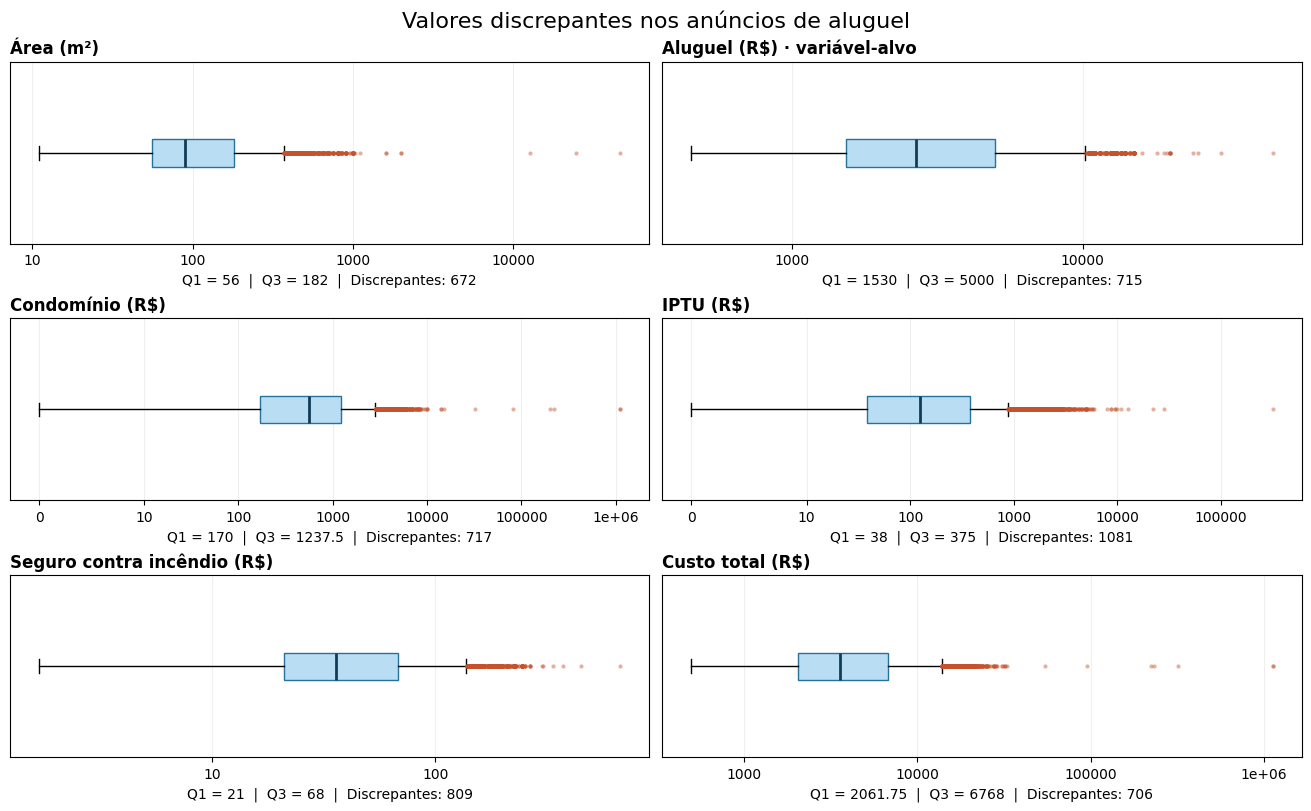

In [40]:
import matplotlib.pyplot as plt
from matplotlib.ticker import StrMethodFormatter

rotulos = {
    "area": "Área (m²)",
    "rent amount (R$)": "Aluguel (R$) · variável-alvo",
    "hoa (R$)": "Condomínio (R$)",
    "property tax (R$)": "IPTU (R$)",
    "fire insurance (R$)": "Seguro contra incêndio (R$)",
    "total (R$)": "Custo total (R$)",
}

# Mantém a lista disponível para as células seguintes
colunas_analisadas = list(rotulos)

fig, eixos = plt.subplots(3, 2, figsize=(13, 8), layout="constrained")
fig.suptitle("Valores discrepantes nos anúncios de aluguel", fontsize=16)

for eixo, (coluna, rotulo) in zip(eixos.flat, rotulos.items()):
    valores = dados_tratados[coluna].dropna()
    q1, q3 = valores.quantile([0.25, 0.75])
    iqr = q3 - q1
    discrepantes = (
        (valores < q1 - 1.5 * iqr) | (valores > q3 + 1.5 * iqr)
    ).sum()

    eixo.boxplot(
        valores,
        orientation="horizontal",
        whis=1.5,
        patch_artist=True,
        boxprops={"facecolor": "#B9DDF3", "edgecolor": "#26729B"},
        medianprops={"color": "#123C56", "linewidth": 2},
        flierprops={
            "marker": "o", "markersize": 3,
            "markerfacecolor": "#C5522D", "markeredgecolor": "none", "alpha": 0.45,
        },
    )

    eixo.set_xscale("symlog", linthresh=10)
    eixo.xaxis.set_major_formatter(StrMethodFormatter("{x:g}"))
    eixo.set_title(rotulo, loc="left", fontweight="bold")
    eixo.set_yticks([])
    eixo.set_xlabel(f"Q1 = {q1:g}  |  Q3 = {q3:g}  |  Discrepantes: {discrepantes}")
    eixo.grid(axis="x", alpha=0.2)

plt.show()

Foram usados boxplots, histogramas e estatísticas descritivas para avaliar a distribuição da área e dos valores monetários. O método do Intervalo Interquartil sinalizou 1819 registros fora dos limites esperados em pelo menos uma variável.

Desses, 1133 também apresentaram alertas nas regras de consistência.

## 3.5. Transformação de variáveis categóricas:

Vamos aplicar One-Hot Encoding em city, animal e furniture. Essas variáveis representam categorias sem ordem natural. A codificação cria uma coluna binária para cada categoria e evita, por exemplo, atribuir números às cidades como se houvesse uma ordem entre elas. floor já foi convertido para inteiro e segue com o tratamento definido na seção acima.

In [41]:
import pandas as pd

colunas_categoricas = ["city", "animal", "furniture"]

resumo_categorias = pd.DataFrame({
    "Categorias distintas": dados_tratados[colunas_categoricas].nunique(),
    "Valores nulos": dados_tratados[colunas_categoricas].isna().sum(),
    "Categorias encontradas": [
        ", ".join(sorted(dados_tratados[coluna].dropna().unique()))
        for coluna in colunas_categoricas
    ],
})

display(resumo_categorias)

,Categorias distintas,Valores nulos,Categorias encontradas
city,5,0,"Belo Horizonte, Campinas, Porto Alegre, Rio de..."
animal,2,0,"acept, not acept"
furniture,2,0,"furnished, not furnished"


### Avaliar categorias raras ou pouco frequentes

In [42]:
for coluna in colunas_categoricas:
    contagem = dados_tratados[coluna].value_counts()
    percentual = contagem.div(len(dados_tratados)).mul(100)

    frequencias = pd.DataFrame({
        "Quantidade": contagem,
        "Percentual (%)": percentual.round(2),
        "Pouco frequente": percentual.lt(1),
    })

    print(f"\nVariável: {coluna}")
    display(frequencias)


Variável: city


,Quantidade,Percentual (%),Pouco frequente
city,,,
São Paulo,5887,55.06,False
Rio de Janeiro,1501,14.04,False
Belo Horizonte,1258,11.77,False
Porto Alegre,1193,11.16,False
Campinas,853,7.98,False



Variável: animal


,Quantidade,Percentual (%),Pouco frequente
animal,,,
acept,8316,77.78,False
not acept,2376,22.22,False



Variável: furniture


,Quantidade,Percentual (%),Pouco frequente
furniture,,,
not furnished,8086,75.63,False
furnished,2606,24.37,False


In [43]:
dados_codificados = pd.get_dummies(
    dados_tratados,
    columns=colunas_categoricas,
    dtype=int,
)

novas_colunas = dados_codificados.columns.difference(
    dados_tratados.columns, sort=False
)

print(f"Colunas antes da transformação: {dados_tratados.shape[1]}")
print(f"Colunas depois da transformação: {dados_codificados.shape[1]}")
print(f"Colunas binárias criadas: {len(novas_colunas)}")

display(dados_codificados[novas_colunas].head())

Colunas antes da transformação: 13
Colunas depois da transformação: 19
Colunas binárias criadas: 9


,city_Belo Horizonte,city_Campinas,city_Porto Alegre,city_Rio de Janeiro,city_São Paulo,animal_acept,animal_not acept,furniture_furnished,furniture_not furnished
0,0,0,0,0,1,1,0,1,0
1,0,0,0,0,1,1,0,0,1
2,0,0,1,0,0,1,0,0,1
3,0,0,1,0,0,1,0,0,1
4,0,0,0,0,1,0,1,0,1


Foram avaliadas a quantidade de categorias distintas e a frequência de cada categoria nas variáveis city, animal e furniture. O limiar de 1% foi usado para identificar categorias pouco frequentes. As categorias foram mantidas porque representam informações distintas sobre os anúncios. O One-Hot Encoding foi aplicado para transformar essas variáveis em indicadores binários, sem atribuir uma ordem artificial às categorias. A variável-alvo rent amount (R$) permaneceu numérica.

## 3.6. Transformação de variáveis numéricas

In [44]:
variavel_alvo = "rent amount (R$)"

# Separa o alvo e o custo total, que já inclui o aluguel.
numericas = (
    dados_tratados
    .drop(columns=[variavel_alvo, "total (R$)"])
    .select_dtypes(include="number")
)

resumo_escalas = numericas.agg(["min", "median", "max", "std"]).T
resumo_escalas.columns = ["Mínimo", "Mediana", "Máximo", "Desvio padrão"]
resumo_escalas["Amplitude"] = (
    resumo_escalas["Máximo"] - resumo_escalas["Mínimo"]
)

display(resumo_escalas.sort_values("Amplitude", ascending=False).round(2))

,Mínimo,Mediana,Máximo,Desvio padrão,Amplitude
hoa (R$),0.0,560.0,1117000.0,15592.31,1117000.0
property tax (R$),0.0,125.0,313700.0,3107.83,313700.0
area,11.0,90.0,46335.0,537.02,46324.0
fire insurance (R$),3.0,36.0,677.0,47.77,674.0
floor,1.0,5.0,301.0,6.15,300.0
rooms,1.0,2.0,13.0,1.17,12.0
parking spaces,0.0,1.0,12.0,1.59,12.0
bathroom,1.0,2.0,10.0,1.41,9.0


A necessidade de normalização ou padronização foi avaliada comparando a amplitude e o desvio padrão das variáveis numéricas. As variáveis foram mantidas nas unidades originais porque o modelo inicial escolhido, Random Forest, é baseado em árvores de decisão e não depende de uma escala comum entre os atributos. A variável-alvo permaneceu em reais para que o erro de previsão possa ser interpretado na mesma unidade. Se for testado um modelo sensível à escala, como KNN, a padronização será ajustada somente nos dados de treinamento e aplicada aos dados de teste.

## 4. Balanceamento de classes e Separação dos dados

### 4.1. Separar os dados em treinamento e teste

In [45]:
import pandas as pd
from sklearn.model_selection import GroupShuffleSplit

variavel_alvo = "rent amount (R$)"
preditoras = [
    "city", "area", "rooms", "bathroom",
    "parking spaces", "floor", "animal", "furniture",
]

X = dados_tratados[preditoras].copy()
y = dados_tratados[variavel_alvo].copy()

# Cada perfil idêntico recebe o mesmo código, inclusive quando floor é nulo.
grupos = pd.util.hash_pandas_object(X, index=False)

divisao = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=42)
idx_treino, idx_teste = next(divisao.split(X, y, groups=grupos))

X_treino, X_teste = X.iloc[idx_treino].copy(), X.iloc[idx_teste].copy()
y_treino, y_teste = y.iloc[idx_treino].copy(), y.iloc[idx_teste].copy()
grupos_treino = grupos.iloc[idx_treino]
grupos_teste = grupos.iloc[idx_teste]

print(f"Treinamento: {len(X_treino)} registros ({len(X_treino) / len(X):.1%})")
print(f"Teste: {len(X_teste)} registros ({len(X_teste) / len(X):.1%})")

Treinamento: 8560 registros (80.1%)
Teste: 2132 registros (19.9%)


### 4.2. Avaliar o uso de validação cruzada

In [46]:
from sklearn.model_selection import GroupKFold

validacao_cruzada = GroupKFold(n_splits=5)

for rodada, (idx_ajuste, idx_validacao) in enumerate(
    validacao_cruzada.split(X_treino, y_treino, groups=grupos_treino),
    start=1,
):
    print(
        f"Rodada {rodada}: {len(idx_ajuste)} registros para ajuste "
        f"e {len(idx_validacao)} para validação."
    )

Rodada 1: 6848 registros para ajuste e 1712 para validação.
Rodada 2: 6848 registros para ajuste e 1712 para validação.
Rodada 3: 6848 registros para ajuste e 1712 para validação.
Rodada 4: 6848 registros para ajuste e 1712 para validação.
Rodada 5: 6848 registros para ajuste e 1712 para validação.


### 4.3. Avaliar a divisão estratificada

In [47]:
resumo_aluguel = pd.DataFrame({
    "Treinamento (R$)": y_treino.describe(percentiles=[0.25, 0.50, 0.75, 0.95]),
    "Teste (R$)": y_teste.describe(percentiles=[0.25, 0.50, 0.75, 0.95]),
}).drop(index="count")

display(resumo_aluguel.round(2))

,Treinamento (R$),Teste (R$)
mean,3886.98,3933.44
std,3405.84,3419.93
min,500.00,450.00
25%,1500.00,1600.00
50%,2685.00,2640.00
75%,5000.00,4900.00
95%,12000.00,12000.00
max,45000.00,25000.00


### 4.4. Verificar se registros relacionados ficaram no mesmo conjunto

In [48]:
grupos_em_comum = set(grupos_treino) & set(grupos_teste)

print(f"Perfis presentes em treino e teste: {len(grupos_em_comum)}")
assert len(grupos_em_comum) == 0

Perfis presentes em treino e teste: 0


### 4.5. Evitar vazamento de dados

In [49]:
colunas_excluidas = {variavel_alvo, "total (R$)"}

assert colunas_excluidas.isdisjoint(X_treino.columns)
assert colunas_excluidas.isdisjoint(X_teste.columns)
assert X_treino.columns.equals(X_teste.columns)

print("Variáveis preditoras:", X_treino.columns.tolist())
print("Variável-alvo:", y_treino.name)

Variáveis preditoras: ['city', 'area', 'rooms', 'bathroom', 'parking spaces', 'floor', 'animal', 'furniture']
Variável-alvo: rent amount (R$)


Como o valor do aluguel é uma variável numérica, o problema foi tratado como regressão e não exigiu balanceamento de classes ou divisão estratificada por classe.

A base foi dividida em aproximadamente 80% para treinamento e 20% para teste, mantendo perfis idênticos de imóvel no mesmo conjunto. Foi planejada validação cruzada em cinco partes no conjunto de treinamento, com o teste reservado para a avaliação final.

O custo total foi excluído das variáveis preditoras por conter o valor do aluguel, e a codificação das categorias será ajustada somente nos dados destinados ao treinamento em cada etapa.